# Project 01: Customer Churn Prediction & Retention Intelligence

This notebook provides a reproducible end-to-end analysis of the synthetic customer churn dataset. It loads the cleaned profiles and pipeline exports, reproduces cleaning decisions, explores churn patterns, tests hypotheses, engineers features, trains three classifiers, and evaluates a business-cost threshold.

**Currency:** Indian rupees (₹).


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve
)

ROOT = Path.cwd()
DATA = ROOT / "data"
OUTPUT = ROOT / "outputs"
RANDOM_STATE = 2026
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120


## 1. Load source and cleaned data

In [3]:
customers = pd.read_csv(DATA / "customers.csv", parse_dates=["signup_date"])
subscriptions = pd.read_csv(DATA / "subscriptions.csv")
billing = pd.read_csv(DATA / "billing.csv")
support = pd.read_csv(DATA / "support_tickets.csv")
clean = pd.read_csv(OUTPUT / "clean_customer_profiles.csv")

for name, frame in {
    "customers": customers,
    "subscriptions": subscriptions,
    "billing": billing,
    "support_tickets": support,
    "clean_customer_profiles": clean,
}.items():
    print(name, frame.shape)
print(clean.dtypes.to_string())


customers (5000, 5)
subscriptions (5045, 9)
billing (5035, 5)
support_tickets (5000, 5)
clean_customer_profiles (5000, 39)
customer_id                          int64
signup_date                         object
age                                float64
region                              object
churn                                int64
subscription_plan                   object
contract_type                       object
monthly_fee                        float64
tenure_months                        int64
avg_monthly_usage_gb               float64
usage_trend_6m                     float64
payment_method                      object
add_on_count                         int64
last_payment_delay_days            float64
missed_payments_12m                float64
total_late_fees                    float64
billing_issue_count                float64
support_tickets_12m                  int64
open_tickets                         int64
avg_resolution_hours               float64
satisfaction_scor

## 2. Data cleaning

The pipeline removes duplicate customer keys, median-imputes numeric fields, labels categorical missing values as `Unknown`, and winsorizes IQR-identified outliers while retaining audit flags. `churn` is used only as the target.

In [4]:
def iqrr_limits(series):
    clean_series = pd.to_numeric(series, errors="coerce").dropna()
    q1, q3 = clean_series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

numeric_columns = [
    "age", "monthly_fee", "tenure_months", "avg_monthly_usage_gb",
    "usage_trend_6m", "add_on_count", "last_payment_delay_days",
    "missed_payments_12m", "total_late_fees", "billing_issue_count",
    "support_tickets_12m", "open_tickets", "avg_resolution_hours",
    "satisfaction_score",
]

merged = (
    customers.drop_duplicates("customer_id", keep="first")
    .merge(subscriptions.drop_duplicates("customer_id", keep="first"), on="customer_id", how="left", validate="one_to_one")
    .merge(billing.drop_duplicates("customer_id", keep="first"), on="customer_id", how="left", validate="one_to_one")
    .merge(support.drop_duplicates("customer_id", keep="first"), on="customer_id", how="left", validate="one_to_one")
)

for column in numeric_columns:
    merged[column] = pd.to_numeric(merged[column], errors="coerce")
    merged[column] = merged[column].fillna(merged[column].median())

for column in ["region", "subscription_plan", "contract_type", "payment_method"]:
    merged[column] = merged[column].fillna("Unknown").astype("object")

outlier_columns = [
    "monthly_fee", "avg_monthly_usage_gb", "last_payment_delay_days",
    "missed_payments_12m", "support_tickets_12m", "avg_resolution_hours",
]
outlier_limits = {}
for column in outlier_columns:
    lower, upper = iqrr_limits(merged[column])
    outlier_limits[column] = (lower, upper)
    merged[f"{column}_outlier"] = ((merged[column] < lower) | (merged[column] > upper)).astype(int)
    merged[column] = merged[column].clip(lower, upper)

print("Duplicate customers after merge:", merged["customer_id"].duplicated().sum())
print("Missing values:", int(merged.isna().sum().sum()))
pd.DataFrame({
    "column": list(outlier_limits),
    "iqr_lower": [v[0] for v in outlier_limits.values()],
    "iqr_upper": [v[1] for v in outlier_limits.values()],
})


Duplicate customers after merge: 0
Missing values: 0


,column,iqr_lower,iqr_upper
0,monthly_fee,-19.31875,112.97125
1,avg_monthly_usage_gb,-32.01250,117.00750
2,last_payment_delay_days,-13.50000,30.50000
3,missed_payments_12m,-1.50000,2.50000
4,support_tickets_12m,-3.00000,5.00000
5,avg_resolution_hours,-15.65000,61.55000


## 3. Exploratory data analysis

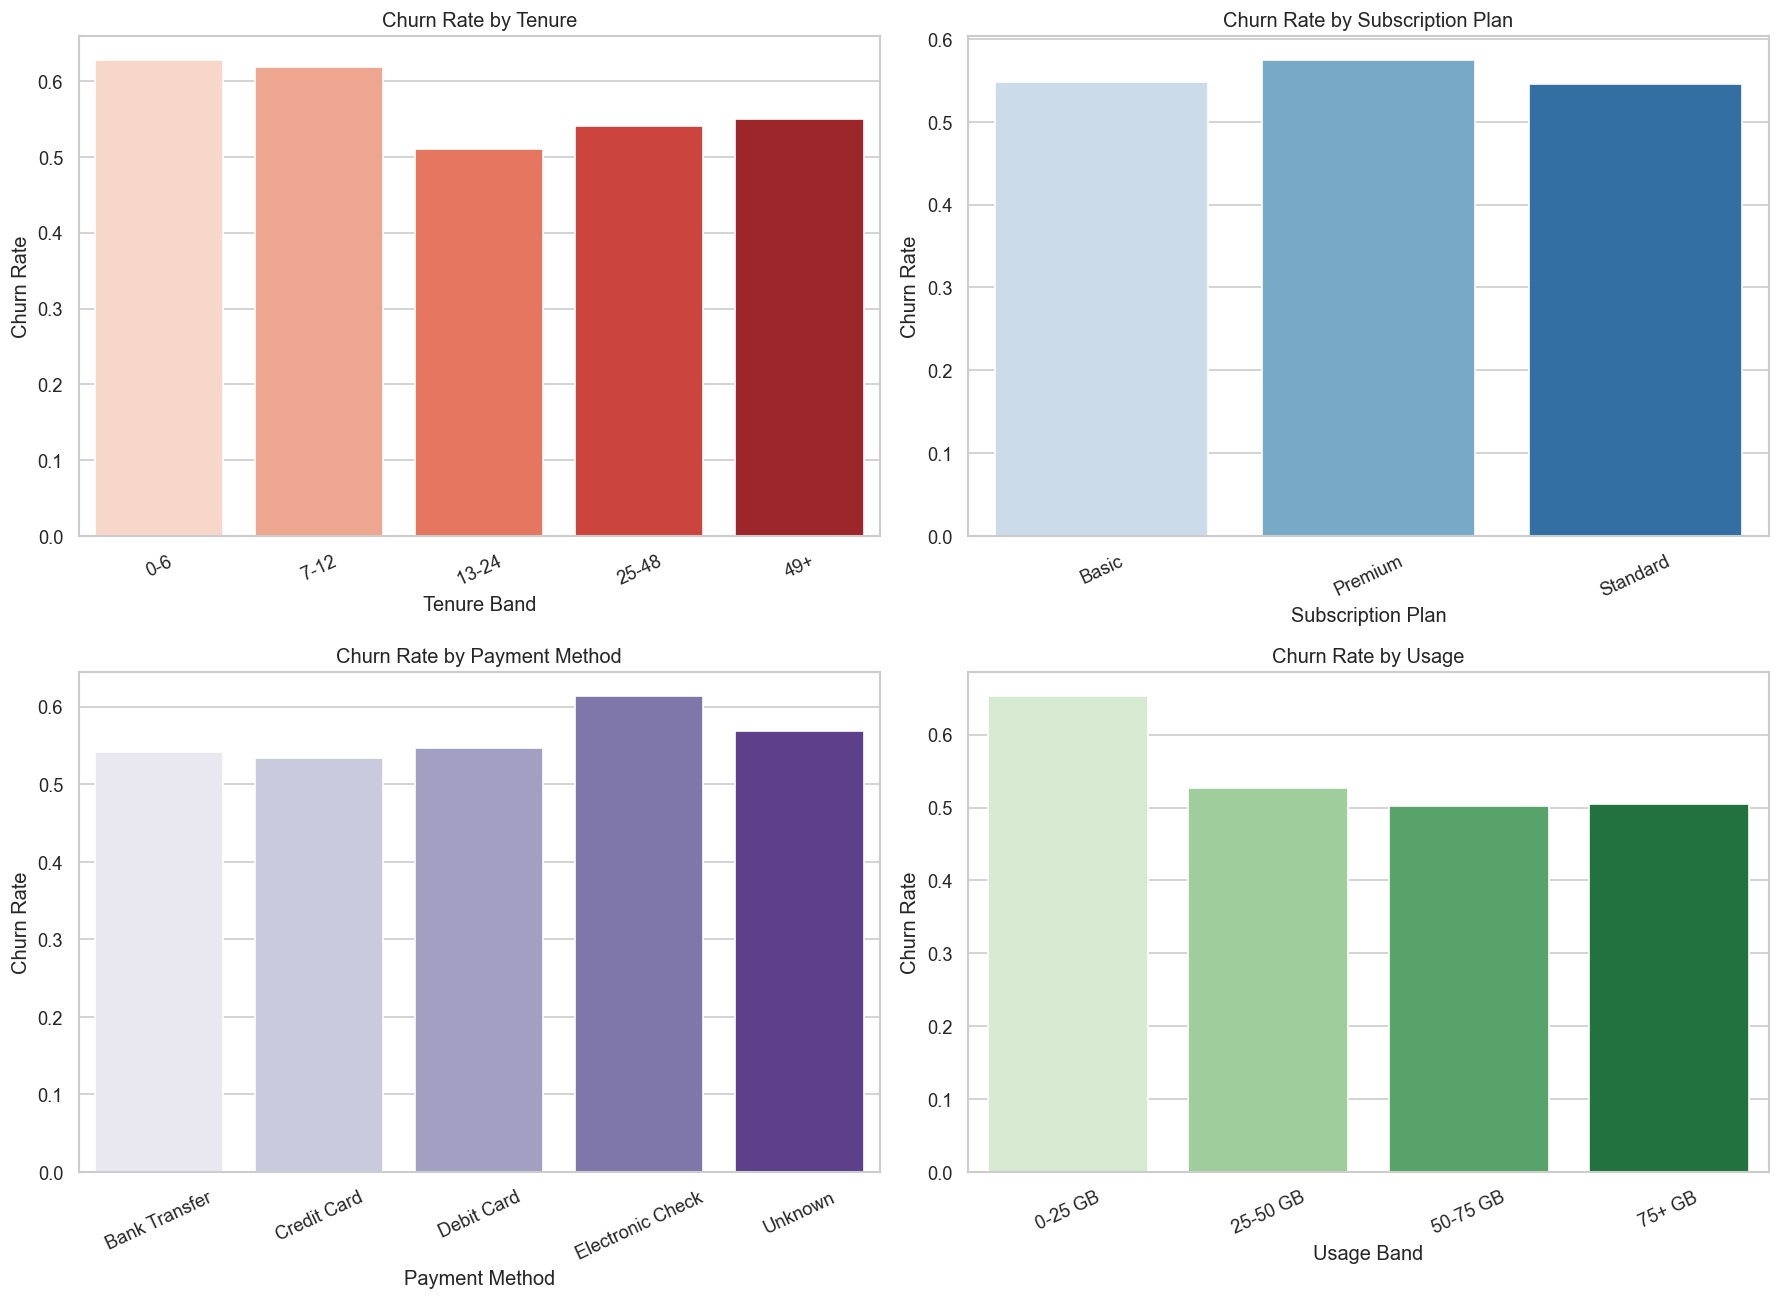

In [5]:
merged["tenure_band"] = pd.cut(
    merged["tenure_months"],
    bins=[-np.inf, 6, 12, 24, 48, np.inf],
    labels=["0-6", "7-12", "13-24", "25-48", "49+"],
)
merged["usage_band"] = pd.cut(
    merged["avg_monthly_usage_gb"],
    bins=[-np.inf, 25, 50, 75, np.inf],
    labels=["0-25 GB", "25-50 GB", "50-75 GB", "75+ GB"],
)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, column, title, palette in [
    (axes[0, 0], "tenure_band", "Churn Rate by Tenure", "Reds"),
    (axes[0, 1], "subscription_plan", "Churn Rate by Subscription Plan", "Blues"),
    (axes[1, 0], "payment_method", "Churn Rate by Payment Method", "Purples"),
    (axes[1, 1], "usage_band", "Churn Rate by Usage", "Greens"),
]:
    summary = merged.groupby(column, observed=True)["churn"].agg(["count", "mean"]).reset_index()
    sns.barplot(data=summary, x=column, y="mean", hue=column, legend=False, palette=palette, ax=ax)
    ax.set_title(title)
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Churn Rate")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


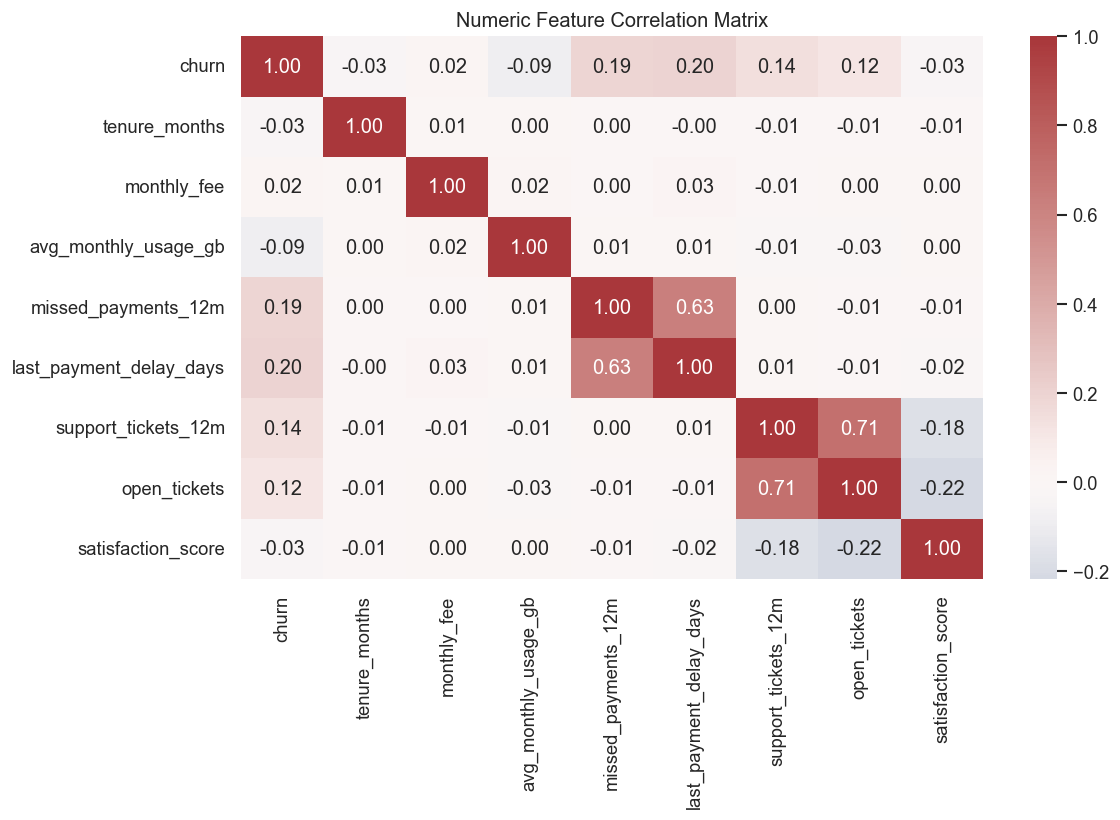

In [6]:
corr_columns = [
    "churn", "tenure_months", "monthly_fee", "avg_monthly_usage_gb",
    "missed_payments_12m", "last_payment_delay_days",
    "support_tickets_12m", "open_tickets", "satisfaction_score",
]
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(merged[corr_columns].corr(numeric_only=True), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Numeric Feature Correlation Matrix")
plt.tight_layout()
plt.show()


## 4. Descriptive statistics and IQR outliers

In [7]:
key_numeric = [
    "tenure_months", "monthly_fee", "avg_monthly_usage_gb",
    "last_payment_delay_days", "support_tickets_12m", "satisfaction_score",
]
descriptive = merged[key_numeric].describe(percentiles=[0.25, 0.5, 0.75]).T
descriptive["median"] = merged[key_numeric].median()
descriptive


,count,mean,std,min,25%,50%,75%,max,median
tenure_months,5000.0,30.541400,17.269984,1.00,16.00,30.00,45.0000,60.0000,30.00
monthly_fee,5000.0,55.754960,26.104744,14.96,30.29,56.90,63.3625,110.7100,56.90
avg_monthly_usage_gb,5000.0,45.322328,28.439302,0.30,23.87,39.21,61.1250,117.0075,39.21
last_payment_delay_days,5000.0,9.294300,7.785914,0.00,3.00,7.00,14.0000,30.5000,7.00
support_tickets_12m,5000.0,0.984200,1.631589,0.00,0.00,0.00,2.0000,5.0000,0.00
satisfaction_score,5000.0,3.598660,0.838843,1.00,3.00,3.60,4.2000,5.0000,3.60


In [8]:
outlier_report = pd.DataFrame({
    "column": list(outlier_limits),
    "lower_limit": [v[0] for v in outlier_limits.values()],
    "upper_limit": [v[1] for v in outlier_limits.values()],
})
outlier_report


,column,lower_limit,upper_limit
0,monthly_fee,-19.31875,112.97125
1,avg_monthly_usage_gb,-32.01250,117.00750
2,last_payment_delay_days,-13.50000,30.50000
3,missed_payments_12m,-1.50000,2.50000
4,support_tickets_12m,-3.00000,5.00000
5,avg_resolution_hours,-15.65000,61.55000


## 5. Statistical hypothesis tests

In [9]:
stat_results = []
for column in ["contract_type", "subscription_plan", "payment_method"]:
    table = pd.crosstab(merged[column], merged["churn"])
    chi2, pvalue, dof, expected = chi2_contingency(table)
    stat_results.append({
        "test": f"Chi-square: churn vs {column}",
        "statistic": chi2,
        "p_value": pvalue,
        "detail": f"dof={dof}",
    })

for column in ["tenure_months", "avg_monthly_usage_gb", "missed_payments_12m", "support_tickets_12m"]:
    retained = merged.loc[merged["churn"] == 0, column].dropna()
    churned = merged.loc[merged["churn"] == 1, column].dropna()
    statistic, pvalue = mannwhitneyu(retained, churned, alternative="two-sided")
    stat_results.append({
        "test": f"Mann-Whitney U: retained vs churned {column}",
        "statistic": statistic,
        "p_value": pvalue,
        "detail": f"retained median={retained.median():.2f}; churned median={churned.median():.2f}",
    })

pd.DataFrame(stat_results)


,test,statistic,p_value,detail
0,Chi-square: churn vs contract_type,1.257663e+02,4.899963e-28,dof=2
1,Chi-square: churn vs subscription_plan,2.717075e+00,2.570364e-01,dof=2
2,Chi-square: churn vs payment_method,1.638293e+01,2.546113e-03,dof=4
3,Mann-Whitney U: retained vs churned tenure_months,3.210036e+06,1.841109e-02,retained median=31.00; churned median=30.00
4,Mann-Whitney U: retained vs churned avg_monthl...,3.451890e+06,1.060215e-12,retained median=41.84; churned median=37.09
5,Mann-Whitney U: retained vs churned missed_pay...,2.582334e+06,3.975222e-38,retained median=0.00; churned median=0.00
6,Mann-Whitney U: retained vs churned support_ti...,2.691044e+06,3.130743e-21,retained median=0.00; churned median=0.00


## 6. Feature engineering

In [10]:
featured = merged.copy()
featured["tenure_band"] = pd.cut(
    featured["tenure_months"], bins=[-np.inf, 6, 12, 24, 48, np.inf],
    labels=["0-6", "7-12", "13-24", "25-48", "49+"],
)
featured["high_payment_delay"] = (featured["last_payment_delay_days"] >= 15).astype(int)
featured["payment_delay_count_12m"] = featured["missed_payments_12m"]
featured["negative_usage_trend"] = (featured["usage_trend_6m"] < 0).astype(int)
featured["usage_decline_rate"] = featured["usage_trend_6m"].clip(-1, 1)
featured["support_contact_frequency"] = featured["support_tickets_12m"]
featured["high_support_contact"] = (featured["support_tickets_12m"] >= 3).astype(int)
featured["month_to_month"] = (featured["contract_type"] == "Month-to-Month").astype(int)
featured["is_two_year"] = (featured["contract_type"] == "Two Year").astype(int)
featured["tenure_years"] = featured["tenure_months"] / 12
featured["low_usage_flag"] = (featured["avg_monthly_usage_gb"] < 25).astype(int)

feature_columns = [
    "age", "region", "subscription_plan", "contract_type", "monthly_fee",
    "tenure_months", "tenure_band", "avg_monthly_usage_gb", "usage_trend_6m",
    "payment_method", "add_on_count", "last_payment_delay_days",
    "missed_payments_12m", "total_late_fees", "billing_issue_count",
    "support_tickets_12m", "open_tickets", "avg_resolution_hours",
    "satisfaction_score", "high_payment_delay", "payment_delay_count_12m",
    "negative_usage_trend", "usage_decline_rate", "support_contact_frequency",
    "high_support_contact", "month_to_month", "is_two_year", "tenure_years",
    "low_usage_flag",
]
X = featured[feature_columns]
y = featured["churn"]

print("Target leakage check:", "churn" in X.columns)
print("Feature shape:", X.shape)


Target leakage check: False
Feature shape: (5000, 29)


## 7. Model development

In [11]:
X_train, X_remaining, y_train, y_remaining = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_validation, X_test, y_validation, y_test = train_test_split(
    X_remaining, y_remaining, test_size=0.50, random_state=RANDOM_STATE, stratify=y_remaining
)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor_template = lambda: ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])

candidates = [
    ("Logistic Regression", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
     {"model__C": [0.1, 1.0, 10.0]}),
    ("Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE),
     {"model__max_depth": [4, 6, 10], "model__min_samples_leaf": [10, 25]}),
    ("Random Forest", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
     {"model__n_estimators": [200], "model__max_depth": [8, 12],
      "model__min_samples_leaf": [10, 20]}),
]

models = {}
for name, estimator, grid in candidates:
    best_model = None
    best_params = None
    best_f1 = -1
    for params in ParameterGrid(grid):
        model = Pipeline([
            ("preprocessor", preprocessor_template()),
            ("model", estimator),
        ])
        model.set_params(**params)
        model.fit(X_train, y_train)
        val_predictions = (model.predict_proba(X_validation)[:, 1] >= 0.5).astype(int)
        val_f1 = f1_score(y_validation, val_predictions)
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_model = model
            best_params = params
    models[name] = best_model
    print(name, "validation F1:", round(best_f1, 4), "parameters:", best_params)


Logistic Regression validation F1: 0.6986 parameters: {'model__C': 1.0}
Decision Tree validation F1: 0.7264 parameters: {'model__max_depth': 4, 'model__min_samples_leaf': 25}
Random Forest validation F1: 0.7084 parameters: {'model__max_depth': 12, 'model__min_samples_leaf': 10, 'model__n_estimators': 200}


## 8. Evaluation at the 0.50 and tuned thresholds

,model,threshold,precision,recall,f1,roc_auc,accuracy
0,Logistic Regression,0.5,0.666110,0.721519,0.692708,0.686028,0.646
1,Decision Tree,0.5,0.615008,0.681736,0.646655,0.610807,0.588
2,Random Forest,0.5,0.647426,0.750452,0.695142,0.684928,0.636


,model,threshold,precision,recall,f1,roc_auc,accuracy,selection
0,Logistic Regression,0.50,0.666110,0.721519,0.692708,0.686028,0.646,Selected model - default threshold
1,Logistic Regression,0.18,0.553000,1.000000,0.712170,0.686028,0.553,Selected model - validation-tuned threshold
2,Decision Tree,0.50,0.615008,0.681736,0.646655,0.610807,0.588,NaN
3,Random Forest,0.50,0.647426,0.750452,0.695142,0.684928,0.636,NaN


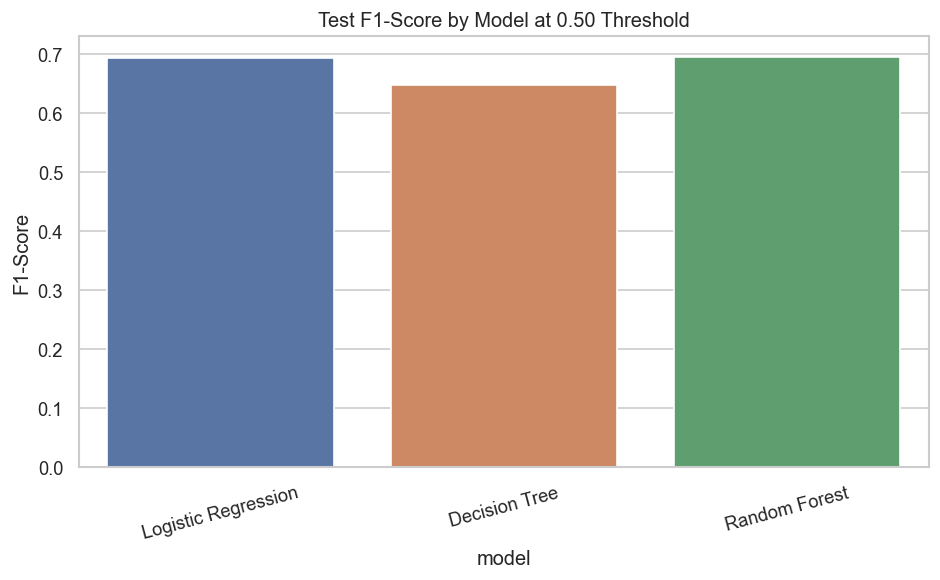

In [12]:
metric_rows = []
for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    metric_rows.append({
        "model": name,
        "threshold": 0.50,
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probabilities),
        "accuracy": (predictions == y_test).mean(),
    })

metrics = pd.DataFrame(metric_rows)
exported_metrics = pd.read_csv(OUTPUT / "model_metrics.csv")
display(metrics)
display(exported_metrics)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=metrics, x="model", y="f1", hue="model", legend=False, ax=ax)
ax.set_title("Test F1-Score by Model at 0.50 Threshold")
ax.set_ylabel("F1-Score")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


,model,threshold,precision,recall,f1,roc_auc,accuracy
0,Logistic Regression,0.18,0.553,1.0,0.71217,0.686028,0.553


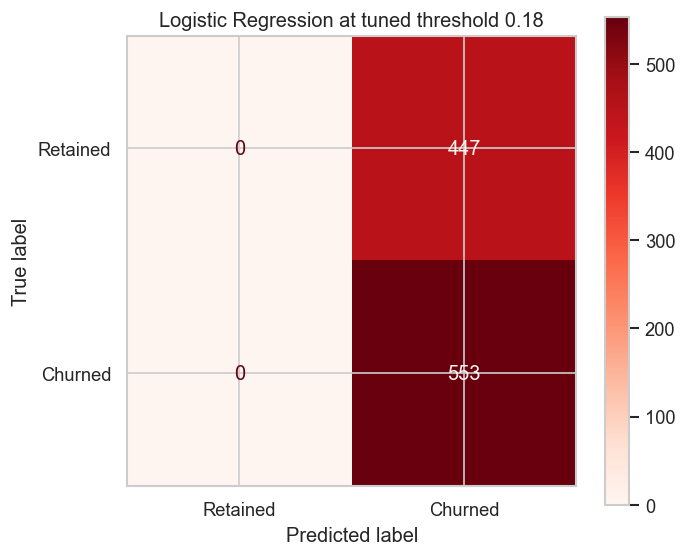

Test confusion matrix counts:
{'TN': np.int64(0), 'FP': np.int64(447), 'FN': np.int64(0), 'TP': np.int64(553)}
selected_model                                        Logistic Regression
optimal_threshold                                                    0.18
validation_min_cost                                                 22300
missed_churn_cost                                                     500
retention_offer_cost                                                   50
justification           Minimizes estimated ₹500 missed-churn cost plu...


In [13]:
threshold_row = pd.read_csv(OUTPUT / "threshold_recommendation.csv").iloc[0]
selected_name = threshold_row["selected_model"]
threshold = float(threshold_row["optimal_threshold"])
selected_model = models[selected_name]

validation_probability = selected_model.predict_proba(X_validation)[:, 1]
test_probability = selected_model.predict_proba(X_test)[:, 1]

validation_predictions = (validation_probability >= threshold).astype(int)
test_predictions = (test_probability >= threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, test_predictions).ravel()
tuned_results = pd.DataFrame([{
    "model": selected_name,
    "threshold": threshold,
    "precision": precision_score(y_test, test_predictions, zero_division=0),
    "recall": recall_score(y_test, test_predictions, zero_division=0),
    "f1": f1_score(y_test, test_predictions, zero_division=0),
    "roc_auc": roc_auc_score(y_test, test_probability),
    "accuracy": (test_predictions == y_test).mean(),
}])
display(tuned_results)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, display_labels=["Retained", "Churned"],
    cmap="Reds", ax=ax,
)
ax.set_title(f"{selected_name} at tuned threshold {threshold:.2f}")
plt.tight_layout()
plt.show()

print("Test confusion matrix counts:")
print({"TN": tn, "FP": fp, "FN": fn, "TP": tp})
print(threshold_row[["selected_model", "optimal_threshold", "validation_min_cost",
                     "missed_churn_cost", "retention_offer_cost", "justification"]].to_string())


## 9. Threshold cost and business interpretation

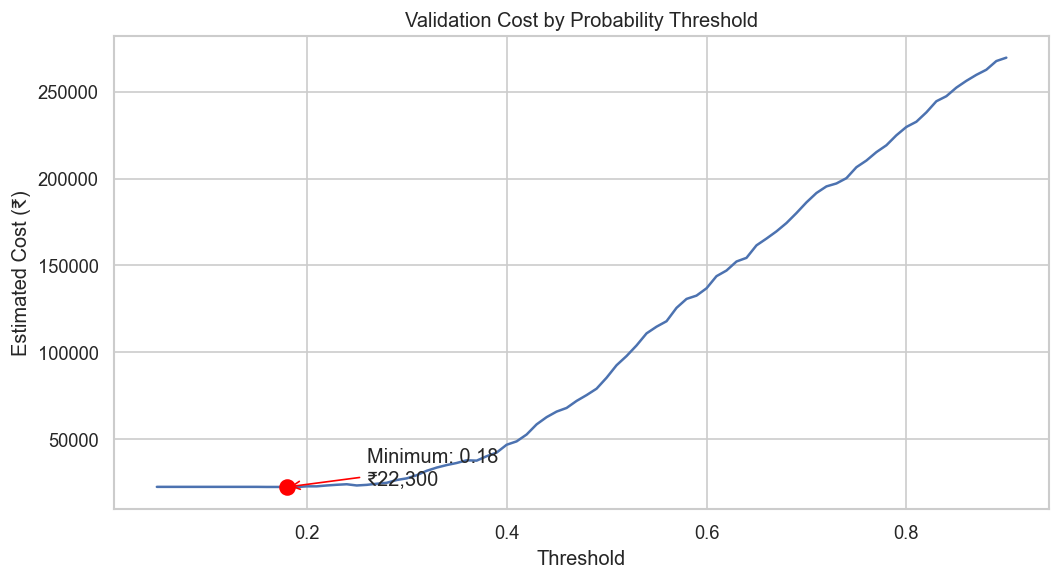

threshold              0.18
cost_inr           22300.00
false_positives      446.00
false_negatives        0.00
Name: 13, dtype: float64

In [14]:
thresholds = np.round(np.arange(0.05, 0.91, 0.01), 2)
cost_rows = []
for candidate_threshold in thresholds:
    predictions = (validation_probability >= candidate_threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_validation, predictions).ravel()
    cost = fn * 500 + fp * 50
    cost_rows.append({
        "threshold": candidate_threshold,
        "cost_inr": cost,
        "false_positives": fp,
        "false_negatives": fn,
    })
cost_curve = pd.DataFrame(cost_rows)
minimum = cost_curve.loc[cost_curve["cost_inr"].idxmin()]

fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=cost_curve, x="threshold", y="cost_inr", ax=ax)
ax.scatter([minimum["threshold"]], [minimum["cost_inr"]], color="red", s=80, zorder=5)
ax.annotate(
    f"Minimum: {minimum['threshold']:.2f}\n₹{minimum['cost_inr']:,.0f}",
    (minimum["threshold"], minimum["cost_inr"]),
    xytext=(minimum["threshold"] + 0.08, minimum["cost_inr"] + 1500),
    arrowprops={"arrowstyle": "->", "color": "red"},
)
ax.set_title("Validation Cost by Probability Threshold")
ax.set_xlabel("Threshold")
ax.set_ylabel("Estimated Cost (₹)")
plt.tight_layout()
plt.show()

minimum


## 10. Feature drivers

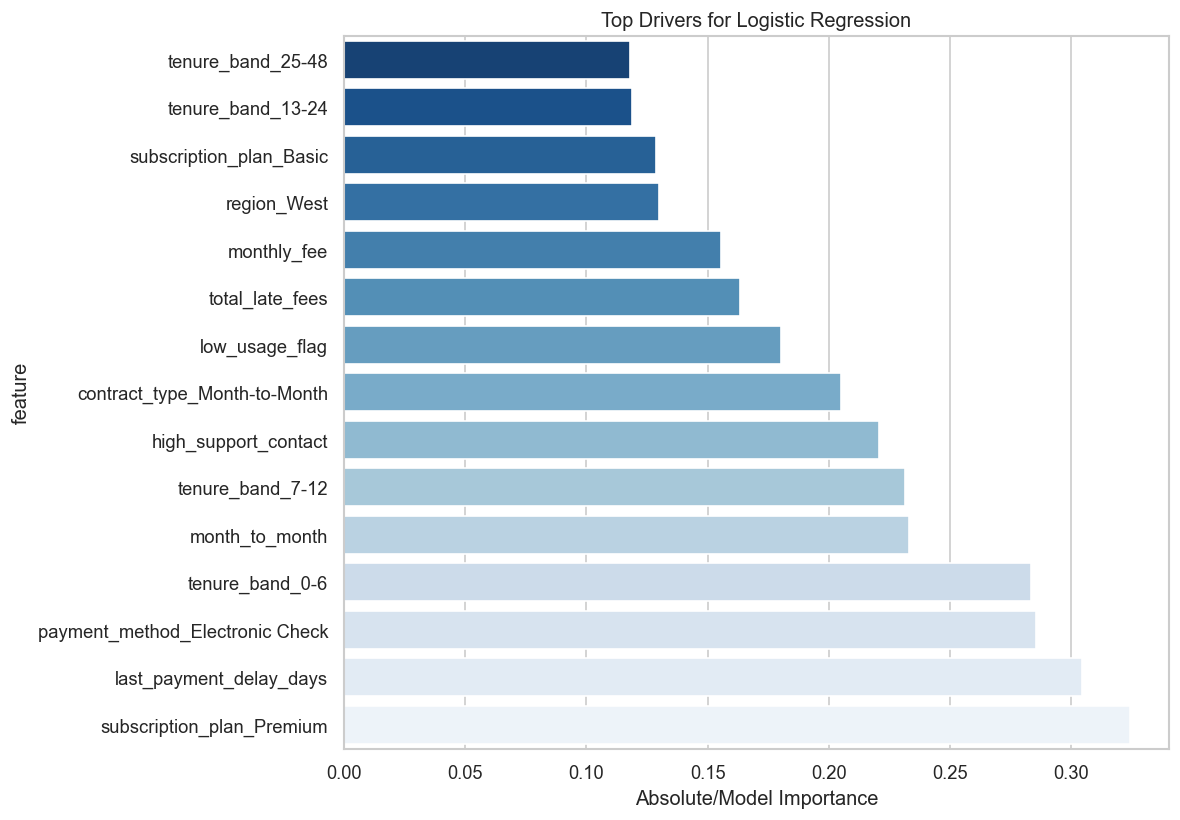

,model,feature,importance
0,Logistic Regression,subscription_plan_Premium,0.324099
1,Logistic Regression,last_payment_delay_days,0.304480
2,Logistic Regression,payment_method_Electronic Check,0.285523
3,Logistic Regression,tenure_band_0-6,0.283529
4,Logistic Regression,month_to_month,0.232920
5,Logistic Regression,tenure_band_7-12,0.231446
6,Logistic Regression,high_support_contact,0.220806
7,Logistic Regression,contract_type_Month-to-Month,0.204890
8,Logistic Regression,low_usage_flag,0.180362
9,Logistic Regression,total_late_fees,0.163505


In [15]:
importance = pd.read_csv(OUTPUT / "feature_importance.csv")
top_importance = (
    importance.loc[importance["model"] == selected_name]
    .drop_duplicates("feature")
    .nlargest(15, "importance")
    .copy()
)
top_importance["feature"] = top_importance["feature"].str.replace(r"^(num|cat)__", "", regex=True)

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=top_importance.iloc[::-1], x="importance", y="feature", hue="feature",
            legend=False, palette="Blues_r", ax=ax)
ax.set_title(f"Top Drivers for {selected_name}")
ax.set_xlabel("Absolute/Model Importance")
plt.tight_layout()
plt.show()

top_importance


## 11. Conclusions

- The Random Forest had the strongest default-threshold F1 in the exported test metrics; the Logistic Regression was the chosen threshold-selection model in the pipeline.
- Contract type, payment method, tenure, payment delays, usage, and support contact patterns show meaningful churn associations.
- The tuned threshold is cost-driven: every missed churner is assumed to cost ₹500, while every unnecessary offer costs ₹50.
- Operational retention lists should use the scored probability and risk segment, not the tuned binary label alone, especially for capacity planning.
